# Ejemplo R - Sonar

* El dataset Sonar (del paquete mlbench en R) contiene información para un problema de clasificación binaria: identificar si un objeto detectado por sonar es una mina o una roca
* Número de observaciones: 208
* Número de variables predictoras: 60
* Todas son numéricas (valores continuos entre 0 y 1)
* Representan la intensidad de la señal de sonar en diferentes frecuencias
* Variable objetivo: Class,Dos categorías: "M" (Mine) y "R" (Rock)

In [2]:
# Instalar y cargar librerías
library(mlbench)
library(caret)
library(rpart)
library(rpart.plot)
library(corrplot)

In [3]:
# 1. Cargar el dataset Sonar
data(Sonar)
str(Sonar)  # 60 variables numéricas + clase binaria

'data.frame':	208 obs. of  61 variables:
 $ V1   : num  0.02 0.0453 0.0262 0.01 0.0762 0.0286 0.0317 0.0519 0.0223 0.0164 ...
 $ V2   : num  0.0371 0.0523 0.0582 0.0171 0.0666 0.0453 0.0956 0.0548 0.0375 0.0173 ...
 $ V3   : num  0.0428 0.0843 0.1099 0.0623 0.0481 ...
 $ V4   : num  0.0207 0.0689 0.1083 0.0205 0.0394 ...
 $ V5   : num  0.0954 0.1183 0.0974 0.0205 0.059 ...
 $ V6   : num  0.0986 0.2583 0.228 0.0368 0.0649 ...
 $ V7   : num  0.154 0.216 0.243 0.11 0.121 ...
 $ V8   : num  0.16 0.348 0.377 0.128 0.247 ...
 $ V9   : num  0.3109 0.3337 0.5598 0.0598 0.3564 ...
 $ V10  : num  0.211 0.287 0.619 0.126 0.446 ...
 $ V11  : num  0.1609 0.4918 0.6333 0.0881 0.4152 ...
 $ V12  : num  0.158 0.655 0.706 0.199 0.395 ...
 $ V13  : num  0.2238 0.6919 0.5544 0.0184 0.4256 ...
 $ V14  : num  0.0645 0.7797 0.532 0.2261 0.4135 ...
 $ V15  : num  0.066 0.746 0.648 0.173 0.453 ...
 $ V16  : num  0.227 0.944 0.693 0.213 0.533 ...
 $ V17  : num  0.31 1 0.6759 0.0693 0.7306 ...
 $ V18  : num  0.

In [4]:
# Calcular matriz de correlación (solo variables numéricas)
cor_matrix <- cor(Sonar[, 1:60])

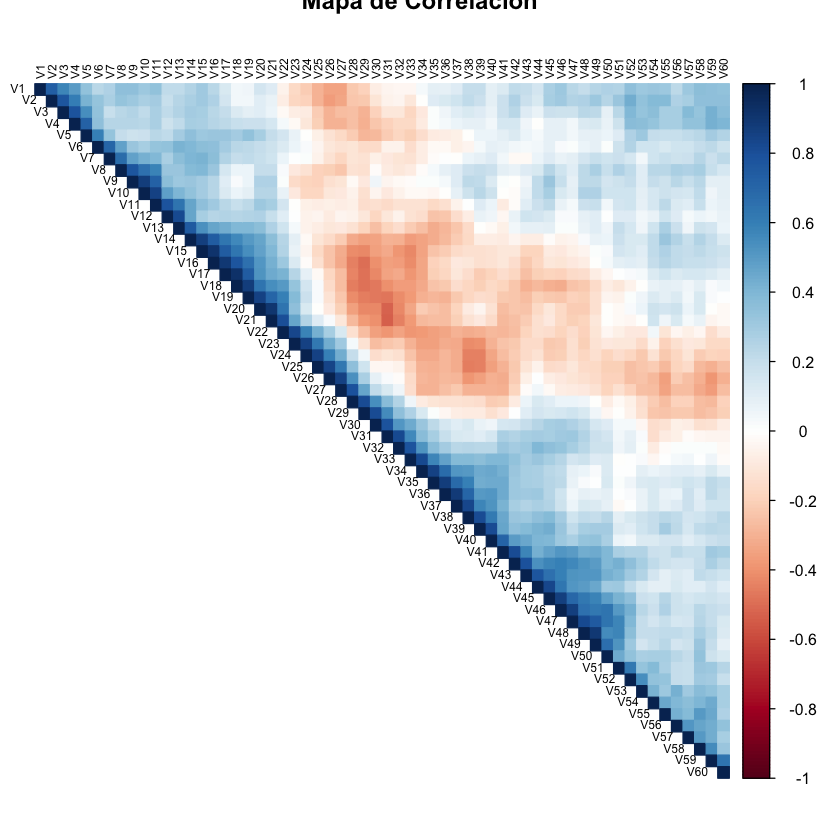

In [5]:
# Graficar mapa de correlación
corrplot(cor_matrix, method = "color", type = "upper",
         tl.cex = 0.6, tl.col = "black", title = "Mapa de Correlación")

In [6]:
summary(Sonar)

       V1                V2                V3                V4         
 Min.   :0.00150   Min.   :0.00060   Min.   :0.00150   Min.   :0.00580  
 1st Qu.:0.01335   1st Qu.:0.01645   1st Qu.:0.01895   1st Qu.:0.02438  
 Median :0.02280   Median :0.03080   Median :0.03430   Median :0.04405  
 Mean   :0.02916   Mean   :0.03844   Mean   :0.04383   Mean   :0.05389  
 3rd Qu.:0.03555   3rd Qu.:0.04795   3rd Qu.:0.05795   3rd Qu.:0.06450  
 Max.   :0.13710   Max.   :0.23390   Max.   :0.30590   Max.   :0.42640  
       V5                V6                V7               V8         
 Min.   :0.00670   Min.   :0.01020   Min.   :0.0033   Min.   :0.00550  
 1st Qu.:0.03805   1st Qu.:0.06703   1st Qu.:0.0809   1st Qu.:0.08042  
 Median :0.06250   Median :0.09215   Median :0.1070   Median :0.11210  
 Mean   :0.07520   Mean   :0.10457   Mean   :0.1217   Mean   :0.13480  
 3rd Qu.:0.10028   3rd Qu.:0.13412   3rd Qu.:0.1540   3rd Qu.:0.16960  
 Max.   :0.40100   Max.   :0.38230   Max.   :0.3729   Max

In [7]:
# 2. Dividir en entrenamiento y prueba (70/30) estratificado
set.seed(123)
trainIndex <- createDataPartition(Sonar$Class, p = 0.7, list = FALSE)
trainData <- Sonar[trainIndex, ]
testData  <- Sonar[-trainIndex, ]

In [8]:
# 3. Entrenar árbol sin restricción (cp = 0 para que crezca al máximo)
modelo <- rpart(Class ~ ., data = trainData, method = "class", control = rpart.control(cp = 0))

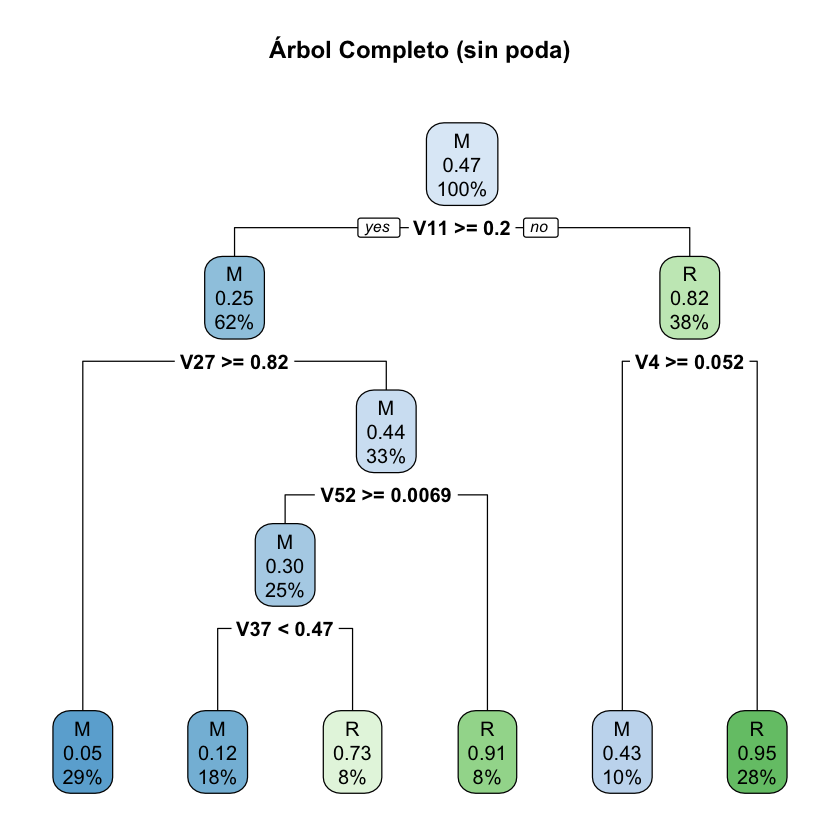

In [9]:
# 4. Visualizar árbol completo
rpart.plot(modelo, main = "Árbol Completo (sin poda)")


Classification tree:
rpart(formula = Class ~ ., data = trainData, method = "class", 
    control = rpart.control(cp = 0))

Variables actually used in tree construction:
[1] V11 V27 V37 V4  V52

Root node error: 68/146 = 0.46575

n= 146 

        CP nsplit rel error  xerror     xstd
1 0.514706      0   1.00000 1.00000 0.088637
2 0.066176      1   0.48529 0.63235 0.080997
3 0.029412      4   0.27941 0.66176 0.082051
4 0.000000      5   0.25000 0.61765 0.080437


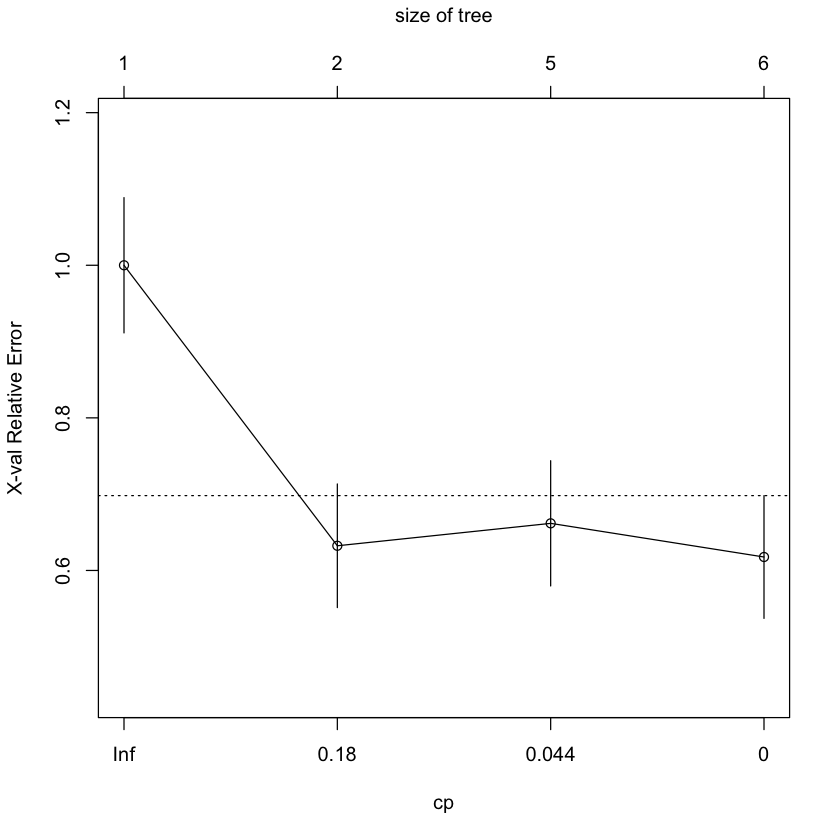

In [10]:
# 5. Ver tabla de complejidad y gráfico para elegir cp óptimo
printcp(modelo)    # Tabla con error de validación cruzada
plotcp(modelo)     # Gráfico para seleccionar cp óptimo

In [11]:
# 6. Seleccionar cp óptimo (mínimo xerror)
cp_opt <- modelo$cptable[which.min(modelo$cptable[,"xerror"]), "CP"]
cat("CP óptimo:", cp_opt, "\n")

CP óptimo: 0 


In [12]:
# 7. Podar el árbol
modelo_podado <- prune(modelo, cp = cp_opt)

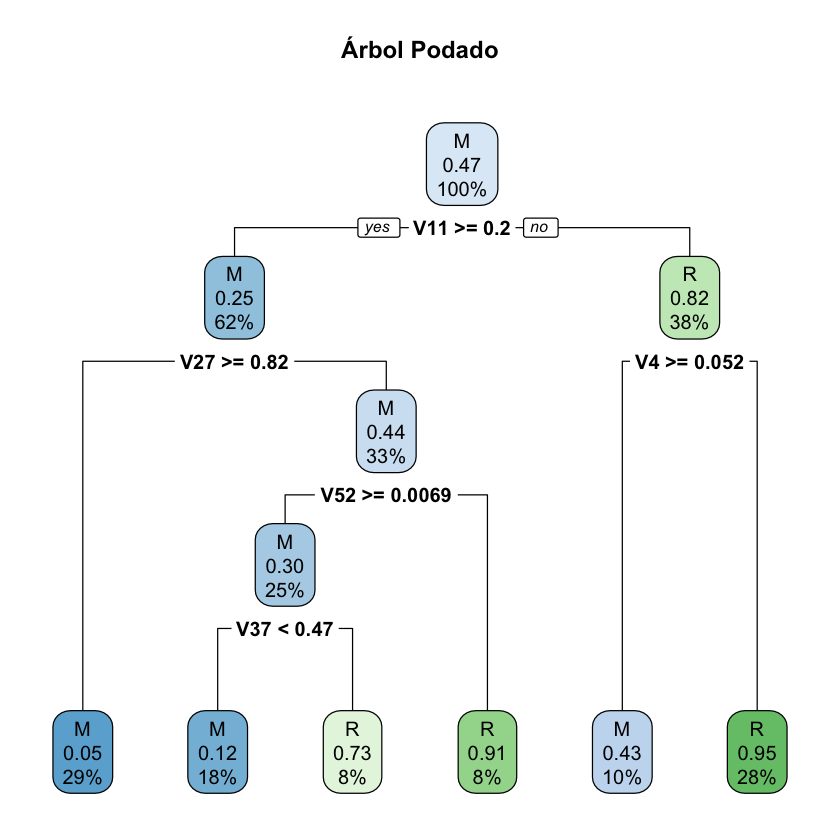

In [13]:
# 8. Visualizar árbol podado
rpart.plot(modelo_podado, main = "Árbol Podado")

In [14]:
# 9. Evaluar desempeño antes y después de la poda
# Predicciones en entrenamiento y prueba
pred_train_full <- predict(modelo, trainData, type = "class")
pred_test_full  <- predict(modelo, testData, type = "class")

pred_train_pod <- predict(modelo_podado, trainData, type = "class")
pred_test_pod  <- predict(modelo_podado, testData, type = "class")

In [15]:
# Matrices de confusión y precisión
conf_train_full <- confusionMatrix(pred_train_full, trainData$Class)
conf_test_full  <- confusionMatrix(pred_test_full, testData$Class)

conf_train_pod <- confusionMatrix(pred_train_pod, trainData$Class)
conf_test_pod  <- confusionMatrix(pred_test_pod, testData$Class)

cat("\n--- Árbol Completo ---\n")
cat("Precisión Entrenamiento:", conf_train_full$overall['Accuracy'], "\n")
cat("Precisión Test:", conf_test_full$overall['Accuracy'], "\n")

cat("\n--- Árbol Podado ---\n")
cat("Precisión Entrenamiento:", conf_train_pod$overall['Accuracy'], "\n")
cat("Precisión Test:", conf_test_pod$overall['Accuracy'], "\n")


--- Árbol Completo ---
Precisión Entrenamiento: 0.8835616 
Precisión Test: 0.7903226 

--- Árbol Podado ---
Precisión Entrenamiento: 0.8835616 
Precisión Test: 0.7903226 


In [16]:
# Mostrar matrices de confusión
cat("\nMatriz Entrenamiento (Podado):\n")
print(conf_train_pod$table)
cat("\nMatriz Test (Podado):\n")
print(conf_test_pod$table)


Matriz Entrenamiento (Podado):
          Reference
Prediction  M  R
         M 72 11
         R  6 57

Matriz Test (Podado):
          Reference
Prediction  M  R
         M 24  4
         R  9 25
